# DDS-8555 Assignment 4: Build Non-Linear Models, Part 2 (Polynomials, Splines, and GAMs)
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. The two Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Section | What it covers |
|---|---|
| Textbook conceptual question (ISLP Ch. 7, Q3) | Part 1 |
| Textbook applied question (ISLP Ch. 7, Q8) | Part 2 |
| Kaggle model 1 (polynomial regression) | Part 3, Model 1 |
| Kaggle model 2 (additive spline model / GAM) | Part 3, Model 2 |
| Non-linear terms in both models | Part 3 |
| Kaggle submission evidence | Screenshot in the paper's appendix |
| Code | This notebook (also on GitHub) |

In [1]:
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, warnings
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/DDS8555/abalone"
    OUT_DIR = "/content/drive/MyDrive/DDS8555/output"
    !pip -q install --no-deps ISLP
else:
    DATA_DIR = os.environ.get("DDS8555_DATA", "data")
    OUT_DIR = os.environ.get("DDS8555_OUT", "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ISLP import load_data
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 55.6 MB/s eta 0:00:00


## Part 1. Conceptual Question 3 (ISLP Chapter 7)
*Paraphrased:* the basis functions are b1(X) = X and b2(X) = (X − 1)²·I(X ≥ 1). The fitted model Y = β0 + β1b1(X) + β2b2(X) gives β̂0 = 1, β̂1 = 1, β̂2 = −2. Sketch the curve for −2 ≤ X ≤ 2.

* **For X < 1:** Ŷ = 1 + X. This is a straight line with slope 1 and intercept 1. It crosses Ŷ = 0 at X = −1 and starts at Ŷ = −1 when X = −2.
* **For X ≥ 1:** Ŷ = 1 + X − 2(X − 1)². This is a downward parabola that joins the line at X = 1 (Ŷ = 2). The two pieces have the same slope there (1), so the curve is smooth. It peaks at X = 1.25 (Ŷ = 2.125) and falls to Ŷ = 1 at X = 2.

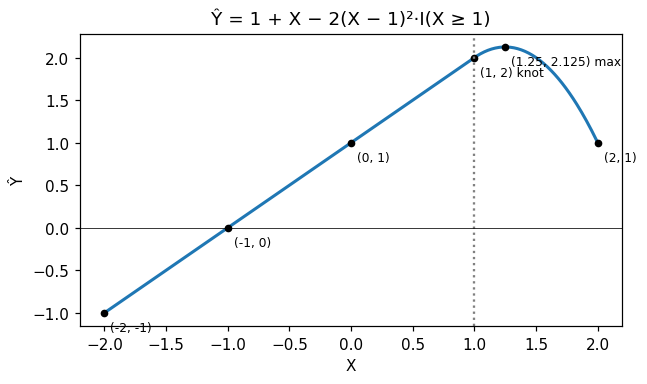

In [2]:
xs = np.linspace(-2, 2, 401)
yh = 1 + xs - 2 * (xs - 1) ** 2 * (xs >= 1)
plt.figure(figsize=(6, 3.6)); plt.plot(xs, yh, lw=2)
for px, lab in [(-2, "(-2, -1)"), (-1, "(-1, 0)"), (0, "(0, 1)"), (1, "(1, 2) knot"), (1.25, "(1.25, 2.125) max"), (2, "(2, 1)")]:
    py = 1 + px - 2 * (px - 1) ** 2 * (px >= 1); plt.plot(px, py, "ko", ms=4); plt.annotate(lab, (px, py), textcoords="offset points", xytext=(4, -12), fontsize=8)
plt.axvline(1, ls=":", c="gray"); plt.axhline(0, c="k", lw=.5)
plt.xlabel("X"); plt.ylabel("Ŷ"); plt.title("Ŷ = 1 + X − 2(X − 1)²·I(X ≥ 1)"); plt.tight_layout(); plt.show()

## Part 2. Applied Question 8 (ISLP Chapter 7): non-linear models for the Auto data
The question asks for some of the chapter's non-linear models on Auto, evidence of non-linear relationships, and plots that justify the answer. Below, mpg is modeled as a function of horsepower with polynomials (degrees 1 to 5, compared by ANOVA and 10-fold CV), a step function, and a natural cubic spline. The last fit is a GAM (generalized additive model) with natural splines in horsepower, weight, and acceleration plus year and origin, compared with the all-linear version.

   df_resid        ssr  df_diff    ss_diff         F  Pr(>F)
0     390.0  9385.9159      0.0        NaN       NaN     NaN
1     389.0  7442.0294      1.0  1943.8865  103.8767  0.0000
2     388.0  7426.4360      1.0    15.5934    0.8333  0.3619
3     387.0  7399.5226      1.0    26.9134    1.4382  0.2312
4     386.0  7223.3717      1.0   176.1509    9.4131  0.0023
10-fold CV MSE by degree: {1: np.float64(24.098), 2: np.float64(19.179), 3: np.float64(19.214), 4: np.float64(19.213), 5: np.float64(18.758)}
                                        R2       AIC
linear hp                            0.606  2361.324
quadratic hp                         0.688  2272.354
step (4 bins) hp                     0.593  2378.390
natural spline hp (df 4)             0.692  2270.311
linear: hp+weight+accel+year+origin  0.819  2065.279
GAM: splines in hp, weight, accel    0.872  1949.885


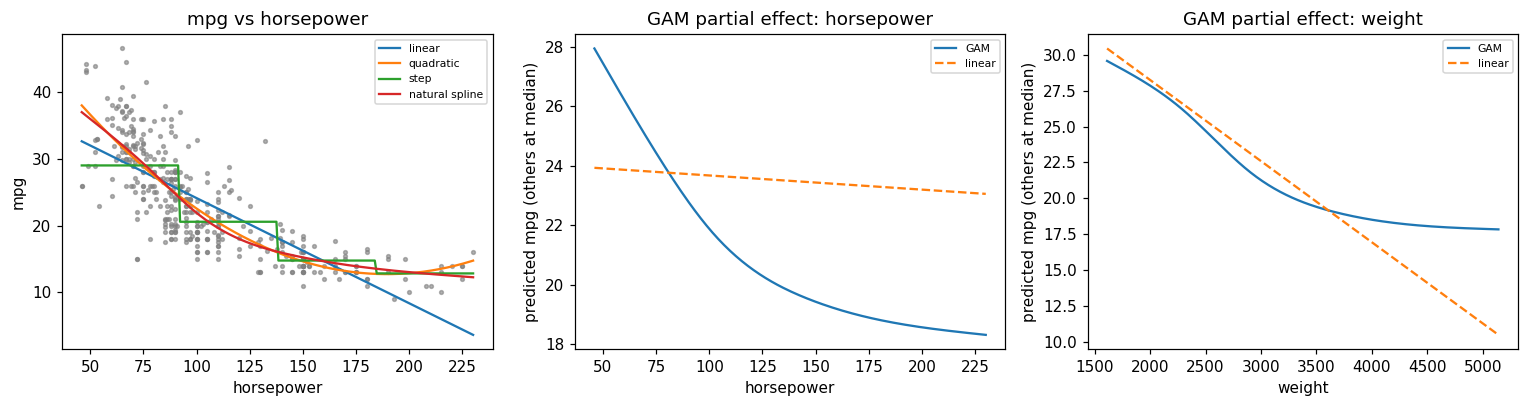

In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold
from statsmodels.stats.anova import anova_lm

auto = load_data("Auto").reset_index(drop=True)
KF10 = KFold(10, shuffle=True, random_state=1)
poly_fits, poly_cv = [], {}
for d in range(1, 6):
    f = "mpg ~ " + " + ".join(["horsepower"] + [f"I(horsepower**{k})" for k in range(2, d + 1)])
    poly_fits.append(smf.ols(f, data=auto).fit())
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    poly_cv[d] = -cross_val_score(pipe, auto[["horsepower"]], auto["mpg"], cv=KF10, scoring="neg_mean_squared_error").mean()
print(anova_lm(*poly_fits).round(4))
print("10-fold CV MSE by degree:", {k: round(v, 3) for k, v in poly_cv.items()})

auto["hp_bin"] = pd.cut(auto["horsepower"], 4)
step = smf.ols("mpg ~ C(hp_bin)", data=auto).fit()
ns_hp = smf.ols("mpg ~ cr(horsepower, df=4, constraints='center')", data=auto).fit()
lin_all = smf.ols("mpg ~ horsepower + weight + acceleration + year + C(origin)", data=auto).fit()
gam = smf.ols("mpg ~ cr(horsepower, df=4, constraints='center') + cr(weight, df=4, constraints='center') + cr(acceleration, df=4, constraints='center') + year + C(origin)", data=auto).fit()
comp = pd.DataFrame({"R2": [poly_fits[0].rsquared, poly_fits[1].rsquared, step.rsquared, ns_hp.rsquared, lin_all.rsquared, gam.rsquared],
                     "AIC": [poly_fits[0].aic, poly_fits[1].aic, step.aic, ns_hp.aic, lin_all.aic, gam.aic]},
                    index=["linear hp", "quadratic hp", "step (4 bins) hp", "natural spline hp (df 4)",
                           "linear: hp+weight+accel+year+origin", "GAM: splines in hp, weight, accel"])
print(comp.round(3))

grid = pd.DataFrame({"horsepower": np.linspace(auto.horsepower.min(), auto.horsepower.max(), 200)})
grid["hp_bin"] = pd.cut(grid["horsepower"], auto["hp_bin"].cat.categories)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(auto.horsepower, auto.mpg, s=6, c="gray", alpha=.6)
ax[0].plot(grid.horsepower, poly_fits[0].predict(grid), label="linear")
ax[0].plot(grid.horsepower, poly_fits[1].predict(grid), label="quadratic")
ax[0].plot(grid.horsepower, step.predict(grid), label="step")
ax[0].plot(grid.horsepower, ns_hp.predict(grid), label="natural spline")
ax[0].set_xlabel("horsepower"); ax[0].set_ylabel("mpg"); ax[0].legend(fontsize=7); ax[0].set_title("mpg vs horsepower")
med = {c: auto[c].median() for c in ["horsepower", "weight", "acceleration", "year"]}
for a, v in zip(ax[1:], ["horsepower", "weight"]):
    g = pd.DataFrame({**{k: [m] * 200 for k, m in med.items()}, "origin": [1] * 200})
    g[v] = np.linspace(auto[v].min(), auto[v].max(), 200)
    a.plot(g[v], gam.predict(g), label="GAM"); a.plot(g[v], lin_all.predict(g), "--", label="linear")
    a.set_xlabel(v); a.set_ylabel("predicted mpg (others at median)"); a.legend(fontsize=7); a.set_title(f"GAM partial effect: {v}")
plt.tight_layout(); plt.show()
RESULTS["auto"] = {"poly_cv": poly_cv, "poly_p_quad": float(anova_lm(*poly_fits)["Pr(>F)"].iloc[1]),
                   "r2_lin": poly_fits[0].rsquared, "r2_quad": poly_fits[1].rsquared, "r2_lin_all": lin_all.rsquared,
                   "r2_gam": gam.rsquared, "aic_lin_all": lin_all.aic, "aic_gam": gam.aic}

**Reading Part 2** (deterministic, so the results match on every run). The evidence for non-linearity is clear. mpg falls steeply with horsepower at low power and then levels off. In the ANOVA, adding the quadratic term is highly significant (*F* ≈ 104, *p* < .001), and 10-fold CV error drops from about 24.1 (linear) to 19.2 (quadratic) before rising again for degrees 3 to 5, which overfit. The natural spline (df = 4) matches the quadratic (R² ≈ .69 vs .61 for the line). The four-bin step function fits worst, because it throws away within-bin variation. Across several predictors, the GAM with splines in horsepower, weight, and acceleration raises R² from about .82 to .87 and cuts AIC by more than 100 points compared with the all-linear model. Its partial-effect plots show horsepower and weight effects that flatten out at high values.

## Kaggle data: Regression with an Abalone Dataset (Playground Series S4E4)
The data load and cleaning cell is identical in Assignments 2, 3, and 4, so the three notebooks use the same data.
Put the Kaggle download (the zip, or `train.csv`, `test.csv`, `sample_submission.csv`) in **Google Drive → My Drive → DDS8555 → abalone**. If the files are not there, an upload button appears.

**Cleaning rule (kept the same in A2–A4):** a height of 0 is physically impossible, so it is treated as missing and replaced with the training-set median height for that sex. Nothing else is changed. The target is modeled as log(1 + Rings) because the competition is scored by RMSLE (root mean squared logarithmic error).

**Missing data.** Abalone has no blank cells. A recorded height of 0 is impossible, though, so it is treated as missing (a structural zero). The cleaning cell replaces it with the training-set median for that sex, the same rule used in Assignments 2 and 3. Median imputation within groups is a simple single-imputation method. It is acceptable here because only a handful of rows are affected (see the count printed by the cleaning cell). With more missingness, multiple imputation would be the better choice, because single imputation understates uncertainty.

In [4]:
# ---- Load and clean the Kaggle abalone data (same cell in A2, A3, A4) ----
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in NEED):
    print("Choose the Kaggle zip (or the three CSV files):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
        zipfile.ZipFile(z).extractall(DATA_DIR)
missing = [f for f in NEED if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files in {DATA_DIR}: {missing}"

RENAME = {"whole weight": "whole_wt", "whole weight.1": "shucked_wt", "whole weight.2": "viscera_wt",
          "shucked weight": "shucked_wt", "viscera weight": "viscera_wt", "shell weight": "shell_wt",
          "whole_weight": "whole_wt", "shucked_weight": "shucked_wt", "viscera_weight": "viscera_wt",
          "shell_weight": "shell_wt"}
tidy = lambda d: d.rename(columns=lambda c: RENAME.get(c.strip().lower(), c.strip().lower()))
train_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "train.csv")))
test_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "test.csv")))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
NUM = ["length", "diameter", "height", "whole_wt", "shucked_wt", "viscera_wt", "shell_wt"]
print("train:", train_raw.shape, " test:", test_raw.shape)
print("columns:", list(train_raw.columns))

HEIGHT_MED = train_raw.loc[train_raw.height > 0].groupby("sex")["height"].median()

def prepare(df):
    """Impute impossible zero heights; one-hot Sex with F as the baseline."""
    out = df.copy()
    zero = out["height"] <= 0
    out.loc[zero, "height"] = out.loc[zero, "sex"].map(HEIGHT_MED)
    sex = pd.Categorical(out["sex"], categories=["F", "I", "M"])
    X = pd.concat([out[NUM].astype(float),
                   pd.get_dummies(sex, prefix="sex", drop_first=True, dtype=float).set_index(out.index)], axis=1)
    return X, int(zero.sum())

X, zero_tr = prepare(train_raw)
X_test, zero_te = prepare(test_raw)
y = train_raw["rings"].astype(float)
ylog = np.log1p(y)
print(f"missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
print(f"zero heights imputed: train {zero_tr}, test {zero_te}")
print(f"duplicate rows (excluding id): {int(train_raw.drop(columns='id').duplicated().sum())}")
print("sex counts:", train_raw["sex"].value_counts().to_dict())
print(train_raw[NUM + ["rings"]].describe().T.round(3))
RESULTS["data"] = {"n_train": int(len(X)), "n_test": int(len(X_test)), "zero_height_train": zero_tr,
                   "zero_height_test": zero_te, "missing_train": int(train_raw.isna().sum().sum()),
                   "rings_min": float(y.min()), "rings_max": float(y.max()),
                   "rings_mean": float(y.mean()), "rings_skew": float(y.skew())}

# ---- Shared scoring helpers ----
from sklearn.model_selection import KFold, cross_val_predict
KF = KFold(n_splits=5, shuffle=True, random_state=42)
LO, HI = float(y.min()), float(y.max())

def rmsle(y_true, y_pred):
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))

def cv_rmsle(model, XX, target="log"):
    """5-fold CV RMSLE on the training set. target='log' fits log1p(Rings)."""
    t = ylog if target == "log" else y
    p = cross_val_predict(model, XX, t, cv=KF)
    p = np.expm1(p) if target == "log" else p
    return rmsle(y, np.clip(p, LO, HI))

def write_submission(pred, name):
    sub = pd.DataFrame({sample.columns[0]: test_raw["id"].values,
                        sample.columns[1]: np.clip(pred, LO, HI)})
    path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False)
    print("saved", path, sub.shape)
    if IN_COLAB:
        files.download(path)
    return path

def resid_panel(fitted, resid, title, ax_row):
    ax1, ax2 = ax_row
    ax1.scatter(fitted, resid, s=2, alpha=.25)
    ax1.axhline(0, color="k", lw=.8)
    ax1.set_xlabel("Fitted value"); ax1.set_ylabel("Residual"); ax1.set_title(title + ": residuals vs fitted")
    sm.qqplot(resid, line="s", ax=ax2, markersize=2, alpha=.3)
    ax2.set_title(title + ": normal Q-Q")

def diagnostics(resid, exog):
    """Breusch-Pagan, Durbin-Watson, Jarque-Bera on a fitted model's residuals."""
    bp = het_breuschpagan(resid, sm.add_constant(exog, has_constant="add"))
    jb = jarque_bera(resid)
    return {"bp_stat": float(bp[0]), "bp_p": float(bp[1]), "dw": float(durbin_watson(resid)),
            "jb_stat": float(jb[0]), "skew": float(jb[2]), "kurtosis": float(jb[3])}

train: (90615, 10)  test: (60411, 9)
columns: ['id', 'sex', 'length', 'diameter', 'height', 'whole_wt', 'shucked_wt', 'viscera_wt', 'shell_wt', 'rings']
missing values: train 0, test 0
zero heights imputed: train 6, test 2
duplicate rows (excluding id): 0
sex counts: {'I': 33093, 'M': 31027, 'F': 26495}
              count   mean    std    min    25%    50%     75%     max
length      90615.0  0.517  0.118  0.075  0.445  0.545   0.600   0.815
diameter    90615.0  0.402  0.098  0.055  0.345  0.425   0.470   0.650
height      90615.0  0.135  0.038  0.000  0.110  0.140   0.160   1.130
whole_wt    90615.0  0.789  0.458  0.002  0.419  0.800   1.068   2.826
shucked_wt  90615.0  0.341  0.204  0.001  0.178  0.330   0.463   1.488
viscera_wt  90615.0  0.169  0.101  0.000  0.086  0.166   0.232   0.760
shell_wt    90615.0  0.226  0.130  0.002  0.120  0.225   0.305   1.005
rings       90615.0  9.697  3.176  1.000  8.000  9.000  11.000  29.000


## Part 3. Two non-linear models for Rings (target: log(1 + Rings))
* **Model 1: polynomial regression.** Every measurement enters with polynomial terms up to degree *d*, including the cross-products of degree *d* or less, plus Sex dummies. *d* (1 to 4) is the simplest degree whose 5-fold CV error is within 0.5% of the best. A very light ridge penalty (α = 1 on standardized terms) keeps the high-degree terms numerically stable. With roughly 90,000 rows, this penalty barely changes the fit.
* **Model 2: additive cubic regression splines (a GAM fit by penalized least squares).** Each measurement gets its own cubic B-spline basis with *k* quantile knots. The effects add up with no interactions, plus Sex dummies. *k* (4 to 20) is chosen the same way. Because the model is additive, each measurement's fitted curve can be plotted on its own.

Polynomial degree -> CV RMSLE: {1: 0.1642, 2: 0.15524, 3: 0.15381, 4: 0.1536}
Spline knots      -> CV RMSLE: {4: 0.15507, 6: 0.1548, 8: 0.15469, 10: 0.15458, 14: 0.15452, 20: 0.1543}
Linear baseline (A2-style OLS on log target): 0.16420
Chosen (simplest within 0.5% of best): polynomial degree 3; spline knots 4
polynomial terms at chosen degree: 119


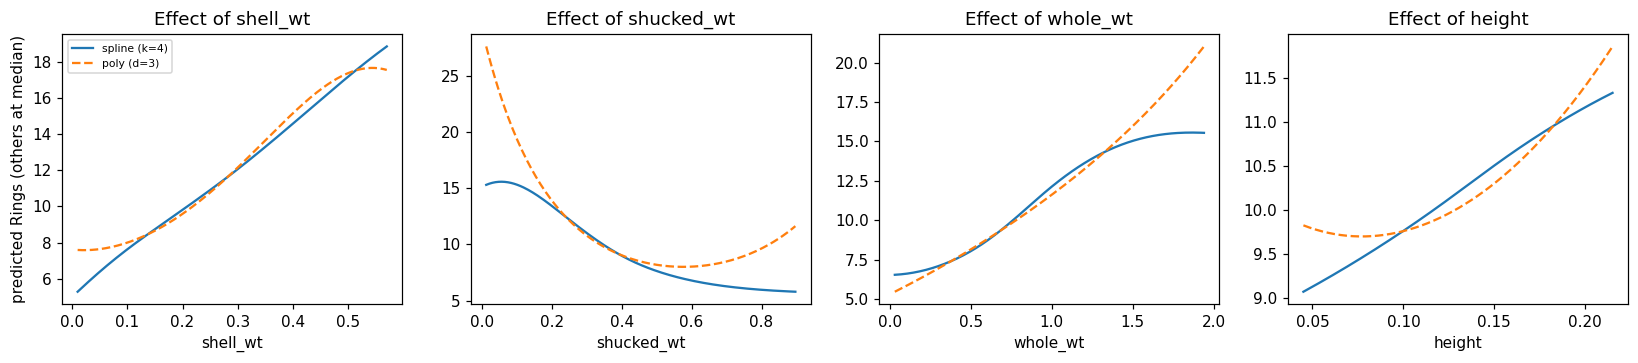

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer, StandardScaler
SEX = ["sex_I", "sex_M"]

def poly_model(d):
    ct = ColumnTransformer([("poly", PolynomialFeatures(d, include_bias=False), NUM), ("sex", "passthrough", SEX)])
    return make_pipeline(ct, StandardScaler(), Ridge(alpha=1.0))

def spline_model(k):
    ct = ColumnTransformer([("spl", SplineTransformer(n_knots=k, degree=3, knots="quantile", extrapolation="linear"), NUM),
                            ("sex", "passthrough", SEX)])
    return make_pipeline(ct, Ridge(alpha=1e-3))

cv_base = cv_rmsle(LinearRegression(), X)
poly_scores = {d: cv_rmsle(poly_model(d), X) for d in (1, 2, 3, 4)}
spline_scores = {k: cv_rmsle(spline_model(k), X) for k in (4, 6, 8, 10, 14, 20)}
# Parsimony rule: the simplest setting whose CV error is within 0.5% of the best (avoids chasing tiny gains)
pick = lambda sc: min(k for k, v in sc.items() if v <= min(sc.values()) * 1.005)
d_best, k_best = pick(poly_scores), pick(spline_scores)
print("Polynomial degree -> CV RMSLE:", {k: round(v, 5) for k, v in poly_scores.items()})
print("Spline knots      -> CV RMSLE:", {k: round(v, 5) for k, v in spline_scores.items()})
print(f"Linear baseline (A2-style OLS on log target): {cv_base:.5f}")
print(f"Chosen (simplest within 0.5% of best): polynomial degree {d_best}; spline knots {k_best}")
n_poly_terms = poly_model(d_best).fit(X.head(50), ylog.head(50))[0].transformers_[0][1].n_output_features_
print("polynomial terms at chosen degree:", n_poly_terms)

m1 = poly_model(d_best).fit(X, ylog)
m2 = spline_model(k_best).fit(X, ylog)

# Partial effects of the additive spline model (others at their medians, Sex = F)
base_row = X.median().to_frame().T; base_row[SEX] = 0.0
show = ["shell_wt", "shucked_wt", "whole_wt", "height"]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, v in zip(ax, show):
    g = pd.concat([base_row] * 200, ignore_index=True)
    g[v] = np.linspace(X[v].quantile(.01), X[v].quantile(.99), 200)
    a.plot(g[v], np.expm1(m2.predict(g)), label=f"spline (k={k_best})")
    a.plot(g[v], np.expm1(m1.predict(g)), "--", label=f"poly (d={d_best})")
    a.set_xlabel(v); a.set_title(f"Effect of {v}")
ax[0].set_ylabel("predicted Rings (others at median)"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A4_fig_partial_effects.png"), dpi=150); plt.show()

### Assumption checks
Both models are linear in their coefficients (the non-linearity lives in the basis functions), so the usual residual assumptions apply. The checks are residuals vs fitted values, normal Q-Q plots, Breusch-Pagan, Durbin-Watson, and Jarque-Bera. The basis expansions are collinear by construction, so the coefficients are not interpreted one at a time. Interpretation uses the fitted curves instead (partial-effect plots above).

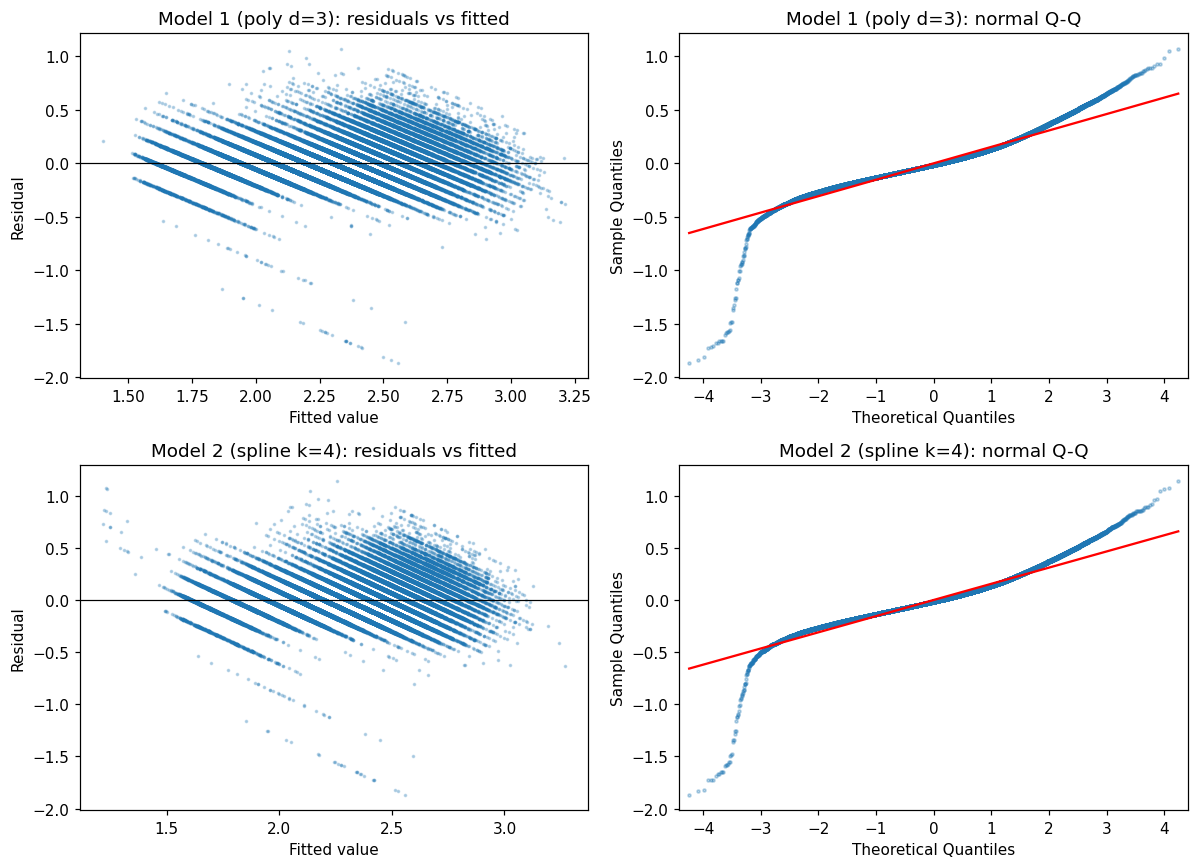

                    bp_stat  bp_p      dw      jb_stat    skew  kurtosis
Model 1 (poly)    1999.7294   0.0  1.9982  115390.7692  0.3006    8.4955
Model 2 (spline)  1691.9916   0.0  1.9998  108519.1613  0.3366    8.3187
saved /content/drive/MyDrive/DDS8555/output/A4_model1_polynomial.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A4_model2_spline_gam.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
f1, f2 = m1.predict(X), m2.predict(X)
r1, r2 = ylog.values - f1, ylog.values - f2
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
resid_panel(f1, r1, f"Model 1 (poly d={d_best})", ax[0]); resid_panel(f2, r2, f"Model 2 (spline k={k_best})", ax[1])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A4_fig_residuals.png"), dpi=150); plt.show()
d1, d2 = diagnostics(r1, X), diagnostics(r2, X)
print(pd.DataFrame({"Model 1 (poly)": d1, "Model 2 (spline)": d2}).T.round(4))

write_submission(np.expm1(m1.predict(X_test)), "A4_model1_polynomial.csv")
write_submission(np.expm1(m2.predict(X_test)), "A4_model2_spline_gam.csv")

RESULTS_FILE = "A4_results.json"
RESULTS["base_cv"] = cv_base
RESULTS["poly"] = {"scores": poly_scores, "d": d_best, "n_terms": int(n_poly_terms), "cv_rmsle": poly_scores[d_best], **d1}
RESULTS["spline"] = {"scores": spline_scores, "k": k_best, "cv_rmsle": spline_scores[k_best], **d2}

In [7]:
# ---- Plain-language reading of the results (printed from the numbers above) ----
print(f"* Both non-linear models beat the linear baseline ({cv_base:.4f}): polynomial {poly_scores[d_best]:.4f}, spline {spline_scores[k_best]:.4f}.")
better = "polynomial" if poly_scores[d_best] < spline_scores[k_best] else "additive spline"
print(f"* The {better} model is better. The polynomial includes cross-products (interactions); the spline model is purely additive.")
shape = {}
for v in show:
    g = pd.concat([base_row] * 3, ignore_index=True); g[v] = X[v].quantile([.1, .5, .9]).values
    p10, p50, p90 = np.expm1(m2.predict(g)); shape[v] = [float(p10), float(p50), float(p90)]
    print(f"* {v}: predicted Rings {p10:.1f} at its 10th percentile, {p50:.1f} at the median, {p90:.1f} at the 90th "
          f"(change {p50-p10:+.1f} in the lower half vs {p90-p50:+.1f} in the upper half)")
RESULTS["spline"]["shape"] = shape
print("  Unequal changes across the two halves mean the effect is curved, so a straight-line model (A2/A3) is mis-specified.")
print(f"* Residual skew {d1['skew']:.2f} / {d2['skew']:.2f}; Breusch-Pagan {d1['bp_stat']:.0f} / {d2['bp_stat']:.0f}: some unequal variance remains.")

* Both non-linear models beat the linear baseline (0.1642): polynomial 0.1538, spline 0.1551.
* The polynomial model is better. The polynomial includes cross-products (interactions); the spline model is purely additive.
* shell_wt: predicted Rings 6.6 at its 10th percentile, 10.4 at the median, 14.6 at the 90th (change +3.8 in the lower half vs +4.3 in the upper half)
* shucked_wt: predicted Rings 15.5 at its 10th percentile, 10.4 at the median, 6.7 at the 90th (change -5.1 in the lower half vs -3.7 in the upper half)
* whole_wt: predicted Rings 6.8 at its 10th percentile, 10.4 at the median, 14.8 at the 90th (change +3.6 in the lower half vs +4.4 in the upper half)
* height: predicted Rings 9.6 at its 10th percentile, 10.4 at the median, 10.9 at the 90th (change +0.8 in the lower half vs +0.6 in the upper half)
  Unequal changes across the two halves mean the effect is curved, so a straight-line model (A2/A3) is mis-specified.
* Residual skew 0.30 / 0.34; Breusch-Pagan 2000 / 1692: so

In [8]:
# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

RESULTS_JSON_START
{"auto": {"poly_cv": {"1": 24.097675731883058, "2": 19.17888986488955, "3": 19.21385952370859, "4": 19.21280701628744, "5": 18.757991658620412}, "poly_p_quad": 8.87826281523342e-22, "r2_lin": 0.6059482578894348, "r2_quad": 0.6875590305127515, "r2_lin_all": 0.8194956076276602, "r2_gam": 0.8715594885981595, "aic_lin_all": 2065.2786291965967, "aic_gam": 1949.8852388468563}, "data": {"n_train": 90615, "n_test": 60411, "zero_height_train": 6, "zero_height_test": 2, "missing_train": 0, "rings_min": 1.0, "rings_max": 29.0, "rings_mean": 9.696794129007339, "rings_skew": 1.2042729726026435}, "base_cv": 0.16419897588615062, "poly": {"scores": {"1": 0.16419891234834816, "2": 0.1552396948229913, "3": 0.15380520225935054, "4": 0.1535992372665797}, "d": 3, "n_terms": 119, "cv_rmsle": 0.15380520225935054, "bp_stat": 1999.7293809061816, "bp_p": 0.0, "dw": 1.9982287965285515, "jb_stat": 115390.76918922756, "skew": 0.3005517747459515, "kurtosis": 8.495516878310541}, "spline": {"scores